### 01. Knowledge Source Gene Set Coverage

In [ ]:
import pandas as pd
import pickle

'''
01. marbach et al., CML
'''
df = pd.read_csv('/nas/project1/PAGE_PJH/01.rawdata/03.regulation/marbach_network/chronic_myelogenous_leukemia_cml_cell_line.txt.gz', sep='\t', header=None)
df.columns = ['tf','gene','weight']
df = df.pivot(index='gene', columns='tf', values='weight')
gs_marbach_cml = df.index.tolist()

'''
02. UnTangled: ensembl converted to gene symbols
'''
gs_untangled = []
null_count = 0
with open('/home/jhpark/page-reproducibility/02_similarity_profiles/intermediate/UnTangled_geneset.txt', 'r') as f:
    for line in f:
        symbol = line.strip('\n')
        if symbol == 'NULL':
            null_count += 1
        elif symbol =='Symbol not found':
            null_count += 1
        else:
            gs_untangled.append(symbol)

'''
03. msigdb hallmark
'''
with open('/nas/project1/PAGE_PJH/01.rawdata/04.function/msigdb_c5.all.v2023.2.Hs.symbols.pkl', 'rb') as f:
	df = pickle.load(f)
gs_msigdb_hallmark = df.index.tolist()

'''
04. stringdb medium
'''
with open('/nas/project1/PAGE_PJH/01.rawdata/05.comprehensive/stringdb.human.medium.pkl', 'rb') as f:
	df = pickle.load(f)

gs_stringdb_medium = df.index.tolist()

'''
05. depmap
'''
with open('/nas/project1/PAGE_PJH/01.rawdata/04.function/depmap_broad_24q2.pkl', 'rb') as f:
	df = pickle.load(f)
gs_depmap = df.index.tolist()

'''
06. periscope
'''
df = pd.read_csv('/nas/project1/PAGE_PJH/01.rawdata/04.function/periscope_a549_profile.csv.gz')
gs_periscope_a549 = df['Metadata_Foci_Barcode_MatchedTo_GeneCode'].tolist()
gs_periscope_a549.remove('nontargeting')

'''
07. scgpt all available
'''
df = pd.read_csv('/nas/project1/PAGE_PJH/01.rawdata/02.expression/scgpt_embedding.csv')
df = df.set_index('Unnamed: 0')
gs_scgpt = df.index.tolist()

'''
08. genept
'''
with open('/nas/project1/PAGE_PJH/01.rawdata/05.comprehensive/genept_ada.pkl', 'rb') as f:
	df = pickle.load(f)
gs_genept = df.index.tolist()


Check redundantly mapped symbols

In [2]:
print("Size of gene symbols")
print(
        f" Marbach CML: {len(gs_marbach_cml)} --> {len(list(set(gs_marbach_cml)))}\n",
        f"Gene-Trait Assoc: {len(gs_untangled)} --> {len(list(set(gs_untangled)))}\n",
        f"MsigDB Hallmark: {len(gs_msigdb_hallmark)} --> {len(list(set(gs_msigdb_hallmark)))}\n",        
        f"StringDB Medium: {len(gs_stringdb_medium)} --> {len(list(set(gs_stringdb_medium)))}\n",
        f"DepMap 24Q2: {len(gs_depmap)} --> {len(list(set(gs_depmap)))}\n",
        f"Periscope a549: {len(gs_periscope_a549)} --> {len(list(set(gs_periscope_a549)))}\n",
        f"SCGPT all: {len(gs_scgpt)} --> {len(list(set(gs_scgpt)))}\n",
        f"GenePT all: {len(gs_genept)} --> {len(list(set(gs_genept)))}"
    )

Size of gene symbols
 Marbach CML: 13248 --> 13248
 Gene-Trait Assoc: 21860 --> 21854
 MsigDB Hallmark: 35485 --> 35485
 StringDB Medium: 19485 --> 19485
 DepMap 24Q2: 18443 --> 18443
 Periscope a549: 20392 --> 20392
 SCGPT all: 36574 --> 36574
 GenePT all: 93800 --> 93800


Remove 6 redundantly mapped genes in UnTangled study

In [3]:
import numpy as np
tmp = pd.DataFrame(np.unique(np.array(gs_untangled), return_counts=True)).T
tmp.columns = ['gene', 'counts']
redundants = tmp[tmp.counts == 2].gene.tolist()
for g in redundants:
    gs_untangled.remove(g)

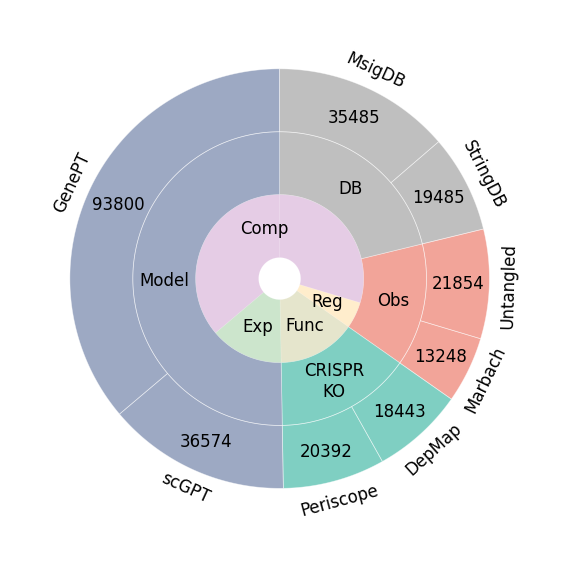

In [ ]:
from pycirclize import Circos
import matplotlib.pyplot as plt

               
n_marbach = len(gs_marbach_cml)
n_untangled = len(gs_untangled)
n_msigdb = len(gs_msigdb_hallmark)
n_stringdb = len(gs_stringdb_medium)
n_depmap = len(gs_depmap)
n_periscope = len(gs_periscope_a549)
n_scgpt = len(gs_scgpt)
n_genept = len(gs_genept)

# Initialize circos sectors
sectors = {
    "MsigDB": n_msigdb,
    "StringDB": n_stringdb,
    "Untangled": n_untangled,
    "Marbach": n_marbach,
    "DepMap": n_depmap,
    "Periscope": n_periscope,
    "scGPT": n_scgpt,
    "GenePT": n_genept
    }
circos = Circos(sectors)


colors = ["grey","grey","#e64b35","#e64b35","#00a087","#00a087","#3c5488","#3c5488"]

groups = [["Marbach", "Untangled"],["MsigDB","StringDB"],["DepMap","Periscope"],["scGPT","GenePT"]]
groupcolors = ["#e64b35","grey","#00a087","#3c5488"]
groupannots = ["Obs", "DB", "CRISPR\nKO", "Model"]

catgroups = [["Marbach"],["Untangled","MsigDB","StringDB"],["DepMap","Periscope"],["scGPT"],["GenePT"]]
catgroupcolors = ["Orange","Purple","Olive","Green","Purple"]
catgroupannots = ["Reg","Comp","Func","Exp","Comp"]
for i, sector in enumerate(circos.sectors):
    # Plot sector axis & name text
    sector.axis(fc="grey", lw=0.5, ec="white", alpha=0)
    # "Observation": grey, "Database": blue, "CRISPR KO": red, "Model embedding": green
    sector.text(f"{sector.name}", size=12)

    track1 = sector.add_track((70, 100))
    track1.axis(fc=colors[i], lw=0.5, ec="white", alpha=0.5)
    track1.text(f"{sector.size}", size=12, adjust_rotation=False)

for i, group in enumerate(groups):
    group_deg_lim = circos.get_group_sectors_deg_lim(group)
    circos.rect(r_lim=(40, 70), deg_lim=group_deg_lim, fc=groupcolors[i], ec="white", lw=0.5, alpha=0.5)
    group_center_deg = sum(group_deg_lim) / 2
    circos.text(groupannots[i], r=55, deg=group_center_deg, adjust_rotation=False, c="black", size=12)

for i, group in enumerate(catgroups):
    group_deg_lim = circos.get_group_sectors_deg_lim(group)
    circos.rect(r_lim=(10, 40), deg_lim=group_deg_lim, fc=catgroupcolors[i], ec="white", lw=0.5, alpha=0.2)
    group_center_deg = sum(group_deg_lim) / 2
    if i != 4:
        if i == 1:
            circos.text(catgroupannots[i], r=25, deg=group_center_deg-70, adjust_rotation=False, c="black", size=12)
        else:
            circos.text(catgroupannots[i], r=25, deg=group_center_deg, adjust_rotation=False, c="black", size=12)

fig = circos.plotfig(figsize=(5,5))
plt.savefig('./figure_out/Fig2A_1.pdf')

/home/jhpark/anaconda3/envs/scgpt_env/lib/python3.9/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/jhpark/anaconda3/envs/scgpt_env/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles[

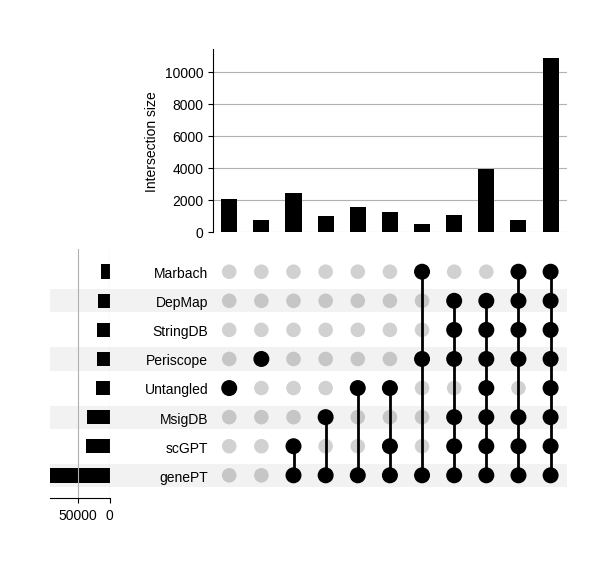

In [ ]:
#dict of sets
sets = {
    'Marbach': list(gs_marbach_cml),
    'MsigDB': list(gs_msigdb_hallmark),
    'DepMap': list(gs_depmap),
    'StringDB': list(gs_stringdb_medium),
    'Periscope': list(gs_periscope_a549),
    'Untangled': list(gs_untangled),
    'scGPT': list(gs_scgpt),
    'genePT': list(gs_genept),
}


import upsetplot
from upsetplot import from_contents, plot
import matplotlib.pyplot as plt
plt.rcParams['font.family']='Liberation Sans'

fig = plt.figure(figsize=(5,5))
upsetplot_input = from_contents(sets)
plot(upsetplot_input, fig=fig, min_subset_size=500, max_subset_size=12000, element_size=30)
plt.savefig('./figure_out/Fig2A_2.pdf')

In [11]:
selected_genes = []
for k in sets.keys():
    if len(selected_genes) == 0:
        selected_genes = sets[k]
    else:
        selected_genes = list(set(selected_genes).intersection(set(sets[k])))
print(len(selected_genes))

10875


In [8]:
np.save('/nas/project1/PAGE_PJH/01.rawdata/00.data_gene_symbols/intersection.npy', selected_genes)

In [12]:
#Setup

import pandas as pd
import numpy as np
from pathlib import Path
from itertools import combinations
#from upsetplot import from_contents, plot as upsetplot_plot

feature_dir = Path("/nas/project1/PAGE_PJH/01.rawdata/00.data_gene_symbols/mrna_symbol") # feature directory
perturbation_dir = Path("/nas/project1/PAGE_PJH/01.rawdata/00.data_gene_symbols/perturb_symbol") #perturbation directory

def load_csv_genes(path):
    # loads csv to set
    df = pd.read_csv(path, header = None, index_col= 0) 
    genes = df.index.tolist()
    try:
        genes.remove('non-target')
        print(path, 'remove non-target')
    except:
        pass

    try:
        genes.remove('off-target')
        print(path, 'remove off-target')
    except:
        pass

    try:
        genes.remove('non')
        print(path, 'remove non')
    except:
        pass
        
    return set(genes)

#Perturbation Target Files and Sets

perturbation_files = {
    "replogle_k562_essential": perturbation_dir / "replogle_k562_essential_perturbation.csv",
    "replogle_k562_gwps":      perturbation_dir / "replogle_k562_gwps_perturbation.csv",
    "replogle_rpe1":           perturbation_dir / "replogle_rpe1_perturbation.csv",
    "nadig_hepg2":             perturbation_dir / "nadig_hepg2_perturbation.csv",
    "nadig_jurkat":            perturbation_dir / "nadig_jurkat_perturbation.csv",
    "southard_rpe1_tf_crispra": perturbation_dir / "southard_rpe1_tf_crispra_effect_perturbation.csv",
}

perturbations = {
    name: load_csv_genes(path)
    for name, path in perturbation_files.items()
}

#mRNA feature Files and Sets 

feature_files = {
    "replogle_k562_essential": feature_dir / "replogle_k562_essential_genes.csv",
    "replogle_k562_gwps":      feature_dir / "replogle_k562_gwps_genes.csv",
    "replogle_rpe1":           feature_dir / "replogle_rpe1_genes.csv",
    "nadig_hepg2":             feature_dir / "nadig_hepg2_genes.csv",
    "nadig_jurkat":            feature_dir / "nadig_jurkat_genes.csv",
    "southard_rpe1_tf_crispra": feature_dir / "southard_rpe1_tf_crispra_effect_genes.csv",
}

features = {
    name: load_csv_genes(path)
    for name, path in feature_files.items()
}

/nas/project1/PAGE_PJH/01.rawdata/00.data_gene_symbols/perturb_symbol/southard_rpe1_tf_crispra_effect_perturbation.csv remove non


In [13]:
# Overlap between dataset function

def overlap_table(source_set: dict, target_set: dict):
    src_names = list(source_set.keys())
    tar_names = list(target_set.keys())

    cross_table = pd.DataFrame(index= src_names, columns= tar_names, dtype=int)
    label_table = pd.DataFrame(index= src_names, columns= tar_names, dtype=object)

    for s in src_names:
        a = set(source_set[s])
        for t in tar_names:
            b = set(target_set[t])
            intersection = len(a&b)
            cross_table.loc[s, t] = intersection/len(a)
            label_table.loc[s, t] = f'{intersection}/\n{len(a)}'

    return cross_table, label_table

In [14]:
#dict of sets
knowledge_sources = {
    'Marbach': gs_marbach_cml,
    'MsigDB': gs_msigdb_hallmark,
    'DepMap': gs_depmap,
    'StringDB': gs_stringdb_medium,
    'Periscope': gs_periscope_a549,
    'Untangled': gs_untangled,
    'scGPT': gs_scgpt,
    'genePT': gs_genept,
    'Intersection': selected_genes
}

In [15]:
import seaborn as sns
perturb_vs_knowledge, label = overlap_table(perturbations, knowledge_sources)
feature_vs_knowledge, label = overlap_table(features, knowledge_sources)

In [16]:
perturb_vs_knowledge = perturb_vs_knowledge.loc[['replogle_k562_gwps','replogle_k562_essential','replogle_rpe1', 'southard_rpe1_tf_crispra','nadig_hepg2','nadig_jurkat']]
feature_vs_knowledge = feature_vs_knowledge.loc[['replogle_k562_gwps','replogle_k562_essential','replogle_rpe1', 'southard_rpe1_tf_crispra','nadig_hepg2','nadig_jurkat']]

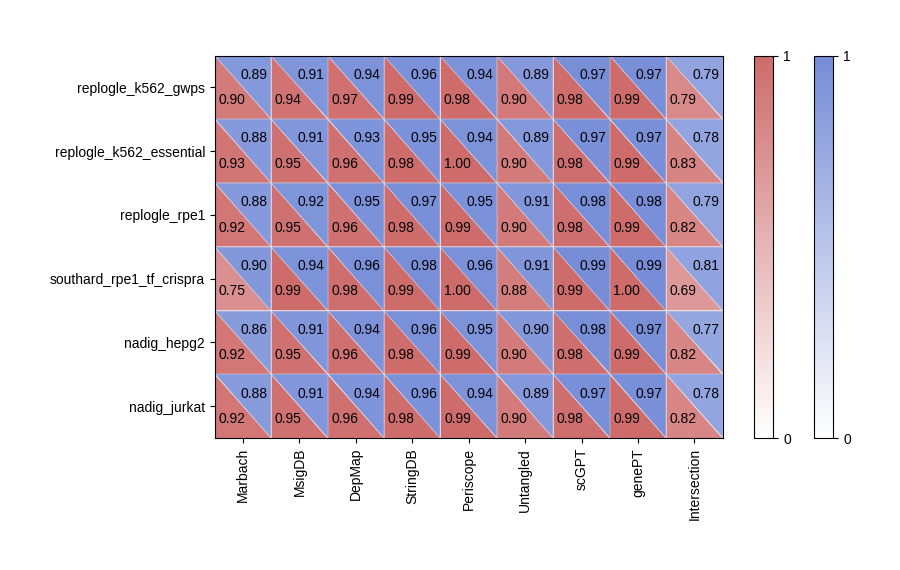

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation
from matplotlib.colors import LinearSegmentedColormap

# Define colors as hex codes
colors = ['#FFFFFF', "#CE6B6B"] 
cmap_name = 'white_to_red'
cmap_reds = LinearSegmentedColormap.from_list(cmap_name, colors)

colors = ['#FFFFFF', "#758CD7"] 
cmap_name = 'white_to_blue'
cmap_blues = LinearSegmentedColormap.from_list(cmap_name, colors)


plt.figure(figsize=(9, 5))
M = 9
N = 6
x = np.arange(M + 1)
y = np.arange(N + 1)
xs, ys = np.meshgrid(x, y)
data1 = perturb_vs_knowledge.values.flatten()
data2 = feature_vs_knowledge.values.flatten()

triangles1 = [(i + (N-j-1)*(M+1), i+1 + (N-j-1)*(M+1), i + ((N-j-1)+1)*(M+1)) for j in range(N) for i in range(M)]
triangles2 = [(i+1 + (N-j-1)*(M+1), i+1 + ((N-j-1)+1)*(M+1), i + ((N-j-1)+1)*(M+1)) for j in range(N) for i in range(M)]
triang1 = Triangulation(xs.ravel(), ys.ravel(), triangles1)
triang2 = Triangulation(xs.ravel(), ys.ravel(), triangles2)
img1 = plt.tripcolor(triang1, data1, cmap=plt.get_cmap(cmap_reds, 10), vmax=1, vmin=0, edgecolors='white')
img2 = plt.tripcolor(triang2, data2, cmap=plt.get_cmap(cmap_blues, 10), vmax=1, vmin=0, edgecolors='white')

for val, dir in zip([data1, data2], [(-1,-1), (1,1)]):
    for i in range(M):
        for j in range(N):
            v = val[i+(N-j-1)*M]
            plt.text(i +0.5 + 0.2 * dir[1], j + 0.5 + 0.2 * dir[0], f'{v:.2f}', color='black', ha='center', va='center')

plt.colorbar(img2, ticks=range(10), pad=-0.05)
plt.colorbar(img1, ticks=range(10))
plt.xlim(x[0], x[-1])
plt.ylim(y[0], y[-1])
plt.xticks(x[:-1]+0.5, rotation=90, labels=perturb_vs_knowledge.columns.tolist())
plt.yticks(y[:-1]+0.5, labels=perturb_vs_knowledge.index.tolist()[::-1])
plt.tight_layout()
plt.savefig('./figure_out/Fig2B.pdf')